## 2. Box-office (Numbers + TMDB)


In [105]:
import pandas as pd
df = pd.read_csv('../../data/merged/df_for_analysis.csv')

In [106]:
df.columns

Index(['title', 'year', 'in_tmdb', 'in_numbers', 'in_rotten', 'n_sources',
       'release_date', 'popularity', 'vote_average', 'vote_count', 'rank',
       'domestic_box_office', 'international_box_office',
       'worldwide_box_office', 'domestic_share', 'genre', 'director',
       'original language', 'summary', 'critic_reviews_count',
       'critic_score_percentage', 'audience_score_percentage',
       'is_audience_rating_verified', 'audience_rating_count',
       'release_date_theaters_month', 'runtime_hour', 'runtime_minutes'],
      dtype='str')

###
1. **Corrélation avec le box-office mondial**  
   Quelles variables sont les plus corrélées au box-office mondial : popularité, nombre de votes ou note moyenne ?


In [107]:
# view popularity, critic_reviews_count, audience_rating_count distributions 
# ignore where values are nan 
import matplotlib.pyplot as plt
dist = df[['popularity', 'critic_reviews_count', 'audience_rating_count']].dropna()

# using iqr method to see if there are outliers in these columns
for col in dist.columns:
    q1 = dist[col].quantile(0.25)
    q3 = dist[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = dist[(dist[col] < lower_bound) | (dist[col] > upper_bound)]
    print(f"Column: {col}, Outliers: {len(outliers)}")  
    print(f"Percentage: {len(outliers)/len(dist)*100:.2f}%")

Column: popularity, Outliers: 188
Percentage: 11.24%
Column: critic_reviews_count, Outliers: 157
Percentage: 9.39%
Column: audience_rating_count, Outliers: 161
Percentage: 9.63%


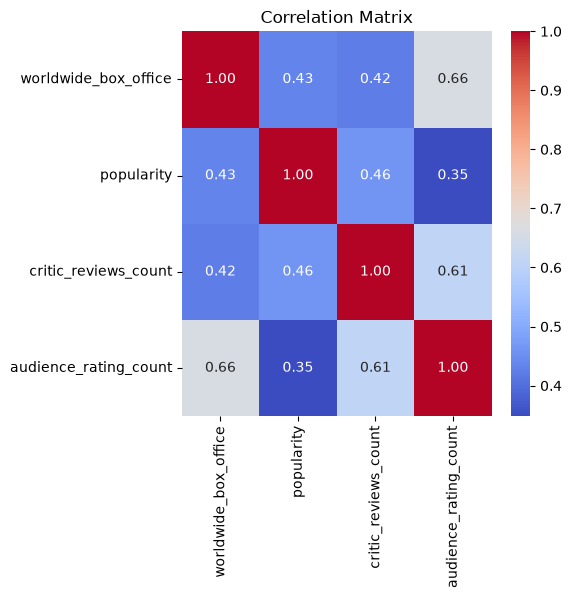

In [108]:
# viewing correlation between worldwide_box_office, popularity, critic_reviews_count, audience_rating_count
# since all these columns belong to the 3 sources : tmdb, numbers and rotten
# we will only select rows where the join was successful for all 3 sources
# wehre n_sources=3
num_cols = ['worldwide_box_office', 'popularity', 'critic_reviews_count', 'audience_rating_count']
full = df[df['n_sources'] == 3]   # movies present in all three sources
full[num_cols].corr(method='spearman') # spearman because data has outliers

# plotting the correlation matrix
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(5, 5))
sns.heatmap(full[num_cols].corr(method='spearman'), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

worldwide_box_office and audience_rating_count is positively correlated 0.66

audience_rating_count and critic_review_count is positively correlated 0.61

popularity doesnt have a strong correlation with any of the columns 

###
2. **Notes et succès commercial**  
   Un film mieux noté rapporte-t-il davantage ? Comparez `tmdb_vote_average`, `rotten_critic_score_percentage` et `numbers_worldwide_box_office`.  
   *Attention : le nombre de votes est lui-même un indicateur de succès.*


In [109]:

import pandas as pd
import numpy as np

pairs = [
    ("vote_average", "worldwide_box_office"),
    ("critic_score_percentage","worldwide_box_office"),
    ("audience_score_percentage","worldwide_box_office"),
    ("vote_count", "worldwide_box_office")
    ]

for x, y in pairs:
    # Keep only observations with both variables available
    data = df[[x, y]].copy()

    for col in [x, y]:
        data[col] = pd.to_numeric(data[col], errors="coerce")

    data = data.dropna()
    
 
    print(f"\n{x} vs {y}")
    print("Number of films:", len(data))

    if len(data) >= 3:
        print("Pearson:", round(data[x].corr(data[y]), 3))
        print("Spearman:", round(data[x].corr(data[y], method="spearman"), 3))



vote_average vs worldwide_box_office
Number of films: 603
Pearson: 0.238
Spearman: 0.235

critic_score_percentage vs worldwide_box_office
Number of films: 191
Pearson: 0.112
Spearman: 0.126

audience_score_percentage vs worldwide_box_office
Number of films: 191
Pearson: 0.215
Spearman: 0.295

vote_count vs worldwide_box_office
Number of films: 603
Pearson: 0.549
Spearman: 0.475


engagement (vote_count) is more closely linked to revenue than critics’ or audience ratings

###
3. **Part du box-office domestique et international**  
   La part du box-office domestique (`numbers_domestic_share`) varie-t-elle selon la langue d’origine, le genre ou l’année ? Quels films dépendent principalement du marché international ?


In [110]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

cols = [
    "title", "year", "domestic_share",
    "domestic_box_office", "international_box_office",
    "worldwide_box_office", "original language", "genre"
]

data = df[cols].copy()

for col in [  # avoid the nan values
    "year", "domestic_share", "domestic_box_office",
    "international_box_office", "worldwide_box_office"
]:
    data[col] = pd.to_numeric(data[col], errors="coerce") 

# Calculate international share as a percentage
data["international_share"] = 100 - data["domestic_share"]



In [111]:
international_threshold= 50
international_films = data[
    data["international_share"] > international_threshold
].sort_values("international_share", ascending=False)

display(international_films[
    ["title", "year", "genre", "original language", "domestic_share", "international_share"]
].head(20))

,title,year,genre,original language,domestic_share,international_share
80436,Vanishing Point,2026.0,NaN,NaN,0.0,100.0
78522,Skazka o tsare Saltane (Сказка о царе Салтане),2026.0,NaN,NaN,0.0,100.0
78239,Scare Out,2026.0,NaN,NaN,0.0,100.0
78158,Salmokji: Whispering Water,2026.0,NaN,NaN,0.0,100.0
77703,Prostokvashino,2026.0,NaN,NaN,0.0,100.0
77327,Panda Plan 2: The Magical Tribe (熊猫计划之部落奇遇记),2026.0,NaN,NaN,0.0,100.0
77154,Once Upon a Time in the Middle East,2026.0,NaN,NaN,0.0,100.0
3780,Eiga Doraemon: Nobita no Getsumen Tansaki,2019.0,NaN,NaN,0.0,100.0
76887,Night King (夜王),2026.0,NaN,NaN,0.0,100.0
4109,Fei Chi Ren Sheng,2019.0,NaN,NaN,0.0,100.0


In [112]:
# Group international films by original language
language_stats = (
    international_films
    .groupby("original language")
    .agg(
        n_films=("title", "count"),
        mean_international_share=("international_share", "mean"),
        median_international_share=("international_share", "median")
    )
    .sort_values("n_films", ascending=False)
)

display(language_stats.round(2))

,n_films,mean_international_share,median_international_share
original language,,,
English,111,62.91,61.10
Chinese,6,99.62,99.65
Hindi,3,93.87,100.00
British English,1,87.20,87.20
Japanese,1,77.30,77.30
Korean,1,97.70,97.70


most international movies are in english which is coherent since most movies are in english, the analysis might be biased because of this, lets check the distributon

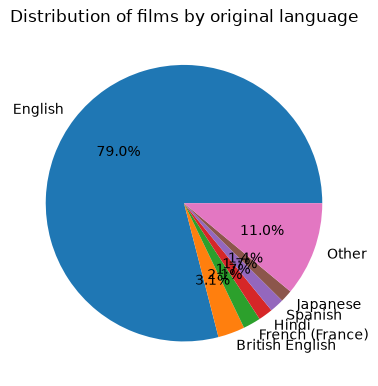

In [113]:
# movie distributions by language
language_counts = data["original language"].value_counts()

# Keep the 6 most frequent languages; group the rest
top_languages = language_counts.head(6)
other_count = language_counts.iloc[6:].sum()

if other_count > 0:
    top_languages["Other"] = other_count

top_languages.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(4, 4),
    ylabel="",
    title="Distribution of films by original language"
)

plt.tight_layout()
plt.show()


In [ ]:
# Split films into individual genres
genre_data = international_films.dropna(subset=["genre"]).copy()

genre_data["genre"] = genre_data["genre"].str.split(",")
genre_data = genre_data.explode("genre")  

genre_data["genre"] = genre_data["genre"].str.strip()

# Group by genre
genre_stats = (
    genre_data
    .groupby("genre")
    .agg(
        n_films=("title", "count"),
        mean_international_share=("international_share", "mean"),
        median_international_share=("international_share", "median")
    )
    .sort_values("n_films", ascending=False)
)

display(genre_stats.round(2))

,n_films,mean_international_share,median_international_share
genre,,,
Adventure,54,67.64,65.80
Comedy,53,65.07,63.40
Mystery & Thriller,44,62.28,58.40
Action,39,65.74,61.10
Fantasy,31,68.44,65.90
Kids & Family,30,67.10,65.00
Drama,29,67.35,63.60
Animation,27,69.84,65.70
Horror,23,61.37,56.60


movies having multiple genres contribute many times to the count

most international movies are in the genre adventure-comedy-mystery

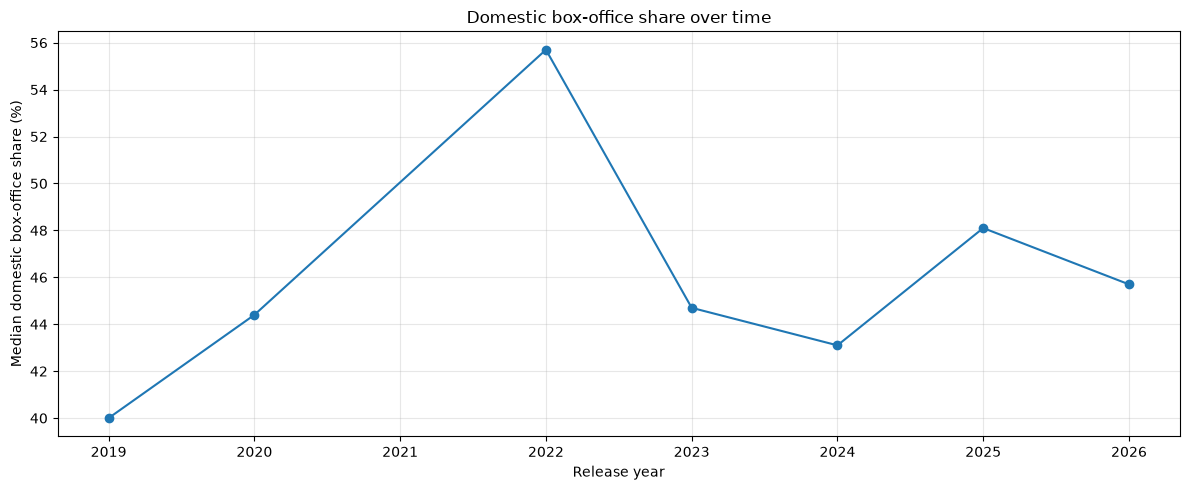

In [87]:
year_stats = (
    data.dropna(subset=["year", "domestic_share"])
    .groupby("year")
    .agg(
        n_films=("title", "count"),
        mean_share=("domestic_share", "mean"),
        median_share=("domestic_share", "median")
    )
    .sort_index()
)

plt.figure(figsize=(12, 5))
plt.plot(
    year_stats.index,
    year_stats["median_share"],
    marker="o"
)
plt.xlabel("Release year")
plt.ylabel("Median domestic box-office share (%)")
plt.title("Domestic box-office share over time")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

downward trend in the domestic share show more contribution from the worldwide one

--> more exposure to other populations

--> from 2020 it started purging: maybe because of covid ? financial crisis --> not enough marketing --> less exposure --> movies are marketed withing the country

then it started reducing after covid starting 2022

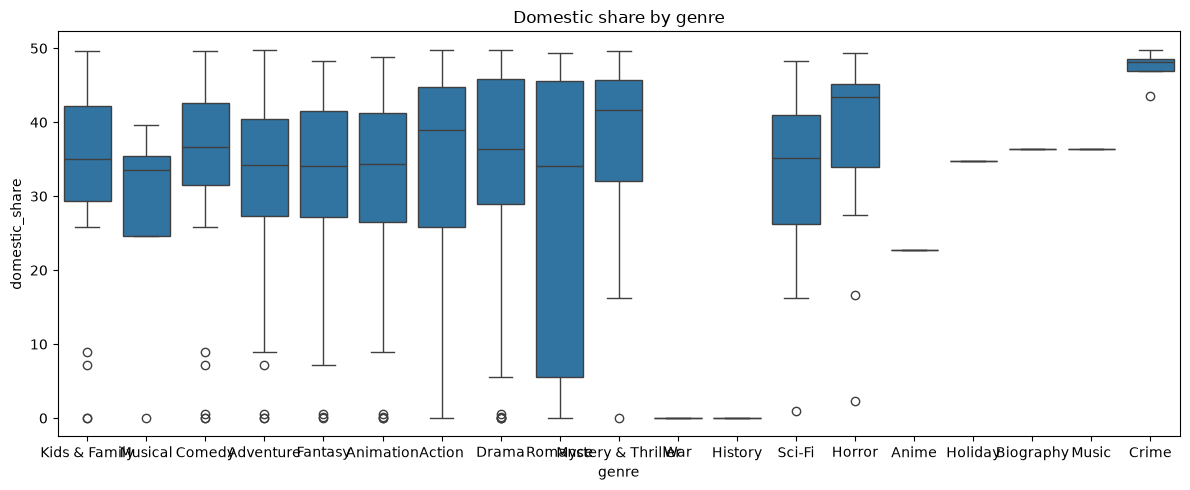

In [103]:
plt.figure(figsize=(12, 5))

sns.boxplot(
    data=genre_data,
    x="genre",
    y="domestic_share"
)

plt.title("Domestic share by genre")
plt.tight_layout()
plt.show()

genres like romance: domestic share goes ranges from 10 to 45 ish with a median of 33 ish : this genre has international exposure --> it might not have been shown in our top genre maybe because there arent enough romance movies in the data
 
 lets check 

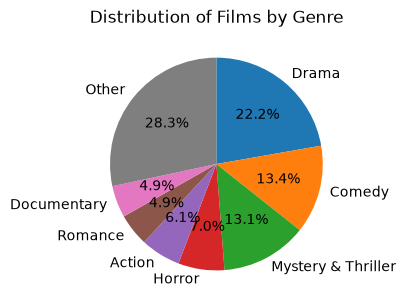

In [115]:
import matplotlib.pyplot as plt

# Split films with multiple genres
genre_counts = (
    data.dropna(subset=["genre"])
    ["genre"]
    .str.split(",")
    .explode()
    .str.strip()
    .value_counts()
)

# Keep the 7 most frequent genres and group the rest
top_genres = genre_counts.head(7).copy()
other_count = genre_counts.iloc[7:].sum()

if other_count > 0:
    top_genres["Other"] = other_count

# Pie chart
plt.figure(figsize=(4, 4))

top_genres.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False
)

plt.title("Distribution of Films by Genre")
plt.ylabel("")
plt.tight_layout()
plt.show()

###
4. **Comparaison entre les films du top 800 de Numbers et le reste de TMDB**  
   Quel est le profil des films présents dans le top 800 de Numbers par rapport aux autres films de TMDB, en termes de popularité et de nombre de votes?

In [116]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure numeric columns are numeric
for col in ["year", "popularity", "vote_count", "rank"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Group 1: films included in The Numbers
numbers_top800 = df[
    (df["in_numbers"] == True) & (df["in_tmdb"] == True)
].copy()

# Group 2: films in TMDB but not in The Numbers
other_tmdb = df[
    (df["in_tmdb"] == True) & (df["in_numbers"] == False)
].copy()

print("Numbers Top 800 films:", len(numbers_top800))
print("Other TMDB films:", len(other_tmdb))


Numbers Top 800 films: 603
Other TMDB films: 78641


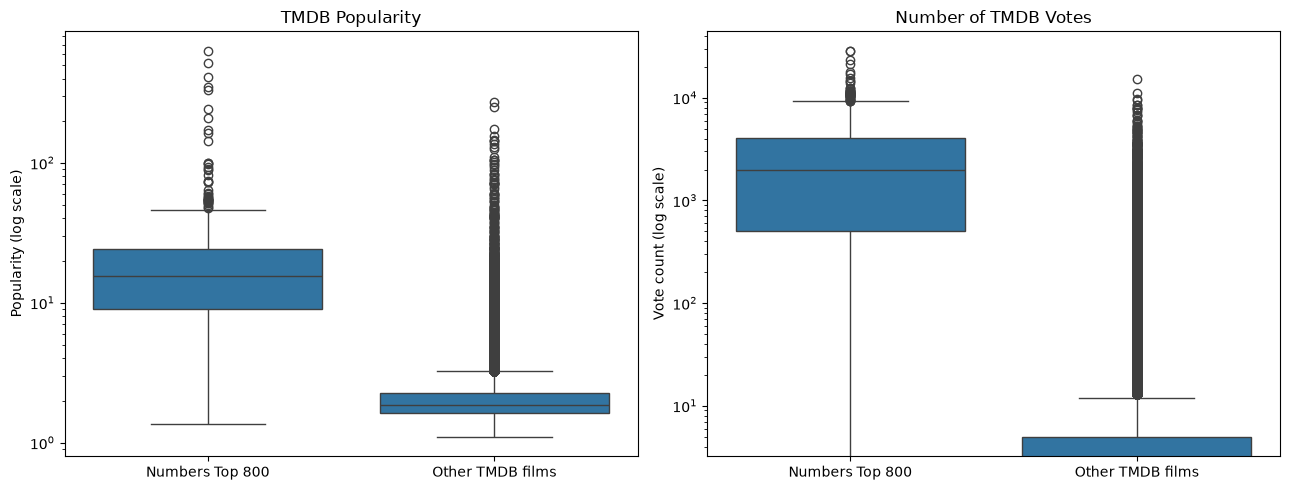

In [122]:
variables = ["popularity", "vote_count", "year"]

numbers_top800["group"] = "Numbers Top 800"
other_tmdb["group"] = "Other TMDB films"

comparison = pd.concat(
    [numbers_top800, other_tmdb],
    ignore_index=True
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(
    data=comparison,
    x="group",
    y="popularity",
    ax=axes[0]
)
axes[0].set_yscale("log")
axes[0].set_title("TMDB Popularity")
axes[0].set_xlabel("")
axes[0].set_ylabel("Popularity (log scale)")

sns.boxplot(
    data=comparison,
    x="group",
    y="vote_count",
    ax=axes[1]
)
axes[1].set_yscale("log")
axes[1].set_title("Number of TMDB Votes")
axes[1].set_xlabel("")
axes[1].set_ylabel("Vote count (log scale)")

plt.tight_layout()
plt.show()


this is consistent because the top 800 movies are more popular and have more engagement from the audience (vote_count)

we can still see that outliers exist in the other tmdb films that are not present in the numbers top 800 movies, thats because numbers store 100 movies per year only

nevertherless the median of tmdb films is still lower and shows consistency : some tmdb movies that popular but were not in the numbers data